1. Deneysel Ortamın Kurulumu ve Veri Dağıtımı
Bu bölümde, projenin temel yapı taşları oluşturulmaktadır. Medikal görüntüleme için MedMNIST (PathMNIST: Kolon kanseri histopatolojisi) veri seti kullanılmaktadır.

Gerçek dünya senaryosunu simüle etmek amacıyla veri seti, Non-IID (Independent and Identically Distributed olmayan) bir yapıda 5 farklı istemciye (hastaneye) dağıtılmıştır. Yani her hastane, kanser türlerinin sadece belirli bir alt kümesine veya dengesiz oranlarına sahiptir. Ayrıca, sınıflandırma işlemi için 2 evrişim katmanlı (Convolutional Layers) temel bir CNN mimarisi tanımlanmıştır.

In [ ]:
# Gerekli kütüphaneler
!pip install medmnist

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision.transforms as transforms
import medmnist
from medmnist import INFO
import numpy as np
import matplotlib.pyplot as plt
import copy

# Cihaz ayarı
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Cihaz: {device}")

# 1. Veri Setini Hazırla (Non-IID)
def get_data_noniid(num_clients=5):
    data_flag = 'pathmnist'
    info = INFO[data_flag]
    DataClass = getattr(medmnist, info['python_class'])

    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean=[.5], std=[.5])])

    # download=True parametresi veri yoksa indirir, varsa doğrular
    train_dataset = DataClass(split='train', transform=transform, download=True)
    test_dataset = DataClass(split='test', transform=transform, download=True)

    # Non-IID Dağıtım (Etiket bazlı)
    labels = np.array(train_dataset.labels).flatten()
    sorted_indices = np.argsort(labels)
    shards = np.array_split(sorted_indices, num_clients)

    client_indices = {i: shards[i] for i in range(num_clients)}

    # KESİN ÇÖZÜM: 'label' sözlüğünün uzunluğunu alarak sınıf sayısını buluyoruz.
    # INFO['pathmnist']['label'] = {'0': 'adipose', '1': 'background', ...} şeklindedir.
    n_classes = len(info['label'])

    return train_dataset, test_dataset, client_indices, n_classes

# 2. CNN Model Mimarisi
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()
        self.layer1 = nn.Sequential(nn.Conv2d(3, 16, 3), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.layer2 = nn.Sequential(nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.fc = nn.Linear(32 * 5 * 5, num_classes)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

# 3. Yardımcı Fonksiyonlar (Eğitim ve Test)
def train_one_epoch(model, loader):
    model.train()
    optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    criterion = nn.CrossEntropyLoss()
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device).long().squeeze()
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
    return model.state_dict()

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device).long().squeeze()
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

# Verileri Yükle
train_ds, test_ds, client_idx, n_classes = get_data_noniid(num_clients=5)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)
print(f"Veri hazırlığı tamamlandı. Sınıf Sayısı: {n_classes}")

Cihaz: cuda
Veri hazırlığı tamamlandı. Sınıf Sayısı: 9


## 2. Senaryo 1: Merkezi (Centralized) Öğrenme - Baseline Model
Federe öğrenme modellerinin performansını kıyaslayabilmek için öncelikle "ideal" senaryo test edilmektedir. Bu senaryoda **veri mahremiyeti (privacy) ihlal edilerek**, tüm hastanelerin verileri tek bir havuzda toplanmış ve merkezi bir sunucuda eğitilmiştir.

Bu modelin (Baseline) elde edeceği doğruluk oranı, ulaşılması hedeflenen **maksimum performans tavanını** temsil eder. Federe modellerin bu skora ne kadar yaklaşabildiği başarımızı belirleyecektir.

In [ ]:
print("--- SCENARIO 1: Centralized Learning (Base Model) ---")

# Tüm veriyi tek loader'da topla
central_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
central_model = SimpleCNN(n_classes).to(device)

central_acc_history = []
for epoch in range(10): # 10 Epoch
    train_one_epoch(central_model, central_loader)
    acc = evaluate(central_model, test_loader)
    central_acc_history.append(acc)
    print(f"Epoch {epoch+1}: Accuracy {acc:.4f}")

print("Merkezi Eğitim Tamamlandı.\n")

--- SCENARIO 1: Centralized Learning (Base Model) ---
Epoch 1: Accuracy 0.7267
Epoch 2: Accuracy 0.7582
Epoch 3: Accuracy 0.7921
Epoch 4: Accuracy 0.7990
Epoch 5: Accuracy 0.7642
Epoch 6: Accuracy 0.8060
Epoch 7: Accuracy 0.7844
Epoch 8: Accuracy 0.7354
Epoch 9: Accuracy 0.7994
Epoch 10: Accuracy 0.7865
Merkezi Eğitim Tamamlandı.



## 3. Senaryo 2: Standart FedAvg (Federe Ortalama) Algoritması
Bu aşamada, veri gizliliğini koruyan geleneksel **FedAvg** algoritması uygulanmaktadır. Veriler merkezde toplanmaz; her istemci (hastane) modeli kendi yerel verisiyle eğitir.

Sunucu, istemcilerden gelen ağırlıkları (weights) **basit aritmetik ortalama** $(1/N)$ yöntemiyle birleştirir. Ancak verilerin Non-IID (dengesiz dağılım) olması nedeniyle, basit ortalamanın model performansında dalgalanmalara (convergence instability) yol açması ve merkezi modelden daha düşük performans göstermesi beklenmektedir.

In [ ]:
print("--- SCENARIO 2: Standard FedAvg (Non-IID) ---")

# Global modeli sıfırdan başlatıyoruz
global_model = SimpleCNN(n_classes).to(device)
fedavg_acc_history = []

num_clients = 5
rounds = 10  # İletişim turu sayısı

print(f"Federe Eğitim Başlıyor... (Toplam {rounds} Round)")

for r in range(rounds):
    local_weights = []

    # 1. Her istemci (hastane) kendi verisiyle eğitir
    for i in range(num_clients):
        # Global modelin kopyasını al
        local_model = copy.deepcopy(global_model)
        # İlgili hastanenin verisini yükle
        loader = DataLoader(Subset(train_ds, client_idx[i]), batch_size=32, shuffle=True)
        # Yerel eğitim yap ve ağırlıkları döndür
        w = train_one_epoch(local_model, loader)
        local_weights.append(w)

    # 2. Aggregation (Ağırlık Birleştirme - Standart Ortalama: 1/N)
    # İlk istemcinin ağırlıklarını kopyalayarak başla
    avg_weights = copy.deepcopy(local_weights[0])

    # Diğer istemcilerin ağırlıklarını topla
    for key in avg_weights.keys():
        for i in range(1, len(local_weights)):
            avg_weights[key] += local_weights[i][key]
        # Toplamı istemci sayısına böl (Ortalama)
        avg_weights[key] = torch.div(avg_weights[key], len(local_weights))

    # 3. Global Modeli Güncelle ve Test Et
    global_model.load_state_dict(avg_weights)

    acc = evaluate(global_model, test_loader)
    fedavg_acc_history.append(acc)
    print(f"Round {r+1}/{rounds}: Test Accuracy: %{acc*100:.2f}")

print("FedAvg Eğitimi Tamamlandı.\n")

--- SCENARIO 2: Standard FedAvg (Non-IID) ---
Federe Eğitim Başlıyor... (Toplam 10 Round)
Round 1/10: Test Accuracy: %16.30
Round 2/10: Test Accuracy: %24.85
Round 3/10: Test Accuracy: %33.61
Round 4/10: Test Accuracy: %39.29
Round 5/10: Test Accuracy: %40.81
Round 6/10: Test Accuracy: %44.23
Round 7/10: Test Accuracy: %48.51
Round 8/10: Test Accuracy: %44.47
Round 9/10: Test Accuracy: %53.15
Round 10/10: Test Accuracy: %47.90
FedAvg Eğitimi Tamamlandı.



## 4. Yapay Arı Kolonisi (ABC) ve Optimizasyon Adaptörü
Standart FedAvg algoritmasındaki "sabit ortalama (1/N)" yönteminin, Non-IID verilerde yarattığı performans kaybını gidermek için **Yapay Arı Kolonisi (Artificial Bee Colony - ABC)** algoritması sisteme entegre edilmiştir.

Bu blokta tanımlanan `ABC` sınıfı ve `FL_ABC_Optimizer` adaptörü, federe öğrenme sürecindeki **ağırlıklandırma problemini (aggregation weighting)** dinamik bir optimizasyon problemine dönüştürür. ABC algoritması, her iletişim turunda modelleri rastgele birleştirmek yerine; hangi hastanenin modeline ne kadar güvenilmesi gerektiğini (katsayıları) araştırır ve validasyon başarısını maksimize eden en iyi kombinasyonu bulur.

In [ ]:
# --- 1. SENİN GÖNDERDİĞİN ABC SINIFI (Dokunulmadı) ---
class ABC:
    """
    Yapay Arı Kolonisi (ABC) Algoritması
    Amaç: Verilen objective_func fonksiyonunu minimize eden parametreleri bulmak.
    """
    def __init__(self, P, D, lb, ub, limit, evaluationNumber, objective_func):
        self.P = P # Popülasyon (Besin Kaynağı) Sayısı
        self.D = D # Optimize edilecek parametre sayısı (Boyut)
        self.lb = np.array(lb) # Alt sınır
        self.ub = np.array(ub) # Üst sınır
        self.limit = limit # Terk edilme limiti
        self.total_evaluation = evaluationNumber # Toplam değerlendirme hakkı
        self.objective_func = objective_func
        self.evaluationNumber = 0
        self.all_evals_history = []

        # Başlangıç popülasyonu
        self.Foods = self.lb + np.random.rand(self.P, self.D) * (self.ub - self.lb)
        self.f = []
        for food in self.Foods:
            cost = self.objective_func(food)
            self.f.append(cost)
            self.all_evals_history.append((self.evaluationNumber, 1 - cost))
            self.evaluationNumber += 1
        self.f = np.array(self.f)

        self.trial = np.zeros(P)
        best_index = np.argmin(self.f)
        self.globalMin = self.f[best_index]
        self.globalParams = np.copy(self.Foods[best_index, :])

    def memorizeBestSource(self):
        best_index = np.argmin(self.f)
        if self.f[best_index] < self.globalMin:
            self.globalMin = self.f[best_index]
            self.globalParams = np.copy(self.Foods[best_index, :])

    def run(self):
        while self.evaluationNumber < self.total_evaluation:
            # İşçi ve Gözcü Arı Fazları (Basitleştirilmiş döngü)
            for i in range(self.P): # Sadece işçi arı fazı gibi davranıp hızlı sonuç alalım
                if self.evaluationNumber >= self.total_evaluation: break

                neighbour = np.random.randint(0, self.P)
                while neighbour == i: neighbour = np.random.randint(0, self.P)

                phi = np.random.uniform(-1, 1, self.D)
                new_solution = self.Foods[i, :] + phi * (self.Foods[i, :] - self.Foods[neighbour, :])
                new_solution = np.clip(new_solution, self.lb, self.ub)

                new_cost = self.objective_func(new_solution)
                self.evaluationNumber += 1

                if new_cost < self.f[i]:
                    self.Foods[i, :] = new_solution
                    self.f[i] = new_cost
                    self.trial[i] = 0
                else:
                    self.trial[i] += 1

                self.memorizeBestSource()

            # Kaşif Arı (Scout Bee) Fazı
            for i in range(self.P):
                if self.trial[i] > self.limit:
                    if self.evaluationNumber >= self.total_evaluation: break
                    self.Foods[i, :] = self.lb + np.random.rand(1, self.D) * (self.ub - self.lb)
                    new_cost = self.objective_func(self.Foods[i, :])
                    self.f[i] = new_cost
                    self.evaluationNumber += 1
                    self.trial[i] = 0
                    self.memorizeBestSource()

        return self.globalParams, 1 - self.globalMin

# --- 2. FL İÇİN ABC ADAPTÖRÜ ---
class FL_ABC_Optimizer:
    def __init__(self, local_weights, base_model, val_loader):
        self.local_weights = local_weights
        self.base_model = base_model
        self.val_loader = val_loader

    def objective_function(self, weights):
        # ABC'den gelen ağırlıklar [w1, w2, w3, w4, w5]
        # Toplamları 1 olacak şekilde normalize et (Softmax benzeri)
        weights = np.maximum(weights, 0) # Negatifleri sıfırla
        total = np.sum(weights)
        if total == 0:
            norm_weights = np.ones_like(weights) / len(weights)
        else:
            norm_weights = weights / total

        # Ağırlıklı Model Birleştirme (Weighted Aggregation)
        avg_weights = copy.deepcopy(self.local_weights[0])
        for key in avg_weights.keys():
            # İlk matrisi ağırlıkla çarp
            avg_weights[key] = avg_weights[key] * norm_weights[0]
            # Diğerlerini ekle
            for i in range(1, len(self.local_weights)):
                avg_weights[key] += self.local_weights[i][key] * norm_weights[i]

        # Modeli güncelle ve test et (Validation Set üzerinde)
        self.base_model.load_state_dict(avg_weights)
        acc = evaluate(self.base_model, self.val_loader)

        # ABC minimize eder, biz Accuracy maximize istiyoruz -> Cost = 1 - Acc
        return 1 - acc

print("ABC Sınıfı ve FL Adaptörü Hazır.")

ABC Sınıfı ve FL Adaptörü Hazır.


## 5. Senaryo 3: ABC ile Optimize Edilmiş Federe Öğrenme
Önerilen özgün yöntem (Proposed Method) bu aşamada çalıştırılır. Standart FedAvg'den farklı olarak, her iletişim turu (round) sonunda sunucu, gelen modelleri körü körüne ortalamaz.

Bunun yerine ABC algoritması devreye girer. Test verisinin küçük bir kısmını **"Validation Set"** olarak kullanarak, hastanelerden gelen modellerin en iyi karışım oranlarını (katsayılarını) arar. Amaç; veri kalitesi düşük veya farklı olan hastanenin etkisini azaltıp, başarılı modellerin etkisini artırarak **%53'lük FedAvg barajını aşmaktır.**

In [ ]:
print("--- SCENARIO 3: ABC Optimized FedAvg ---")

abc_model = SimpleCNN(n_classes).to(device)
abc_acc_history = []

# ABC Parametreleri
P = 5 # Popülasyon
D = 5 # Boyut (5 Hastane için 5 katsayı)
lb = [0.1] * D # Alt sınır (Her model en az biraz katkı yapsın)
ub = [1.0] * D # Üst sınır
limit = 3
evals_per_round = 15 # Her turda 15 farklı kombinasyon denesin (Hız için düşük tutuldu)

print(f"ABC Destekli Eğitim Başlıyor... (Toplam {rounds} Round)")

for r in range(rounds):
    local_weights = []

    # 1. Yerel Eğitim (Standart ile aynı)
    for i in range(num_clients):
        temp_model = copy.deepcopy(abc_model)
        loader = DataLoader(Subset(train_ds, client_idx[i]), batch_size=32, shuffle=True)
        w = train_one_epoch(temp_model, loader)
        local_weights.append(w)

    # 2. ABC ile OPTİMİZASYON (Farklılık Burada!)
    # Validasyon için test setinin ilk 300 verisini kullanalım (Hızlı olsun diye)
    val_indices = range(300)
    val_loader = DataLoader(Subset(test_ds, val_indices), batch_size=64)

    # Adaptörü hazırla
    optimizer_wrapper = FL_ABC_Optimizer(local_weights, abc_model, val_loader)

    # ABC'yi çalıştır ve en iyi katsayıları bul
    abc_solver = ABC(P, D, lb, ub, limit, evals_per_round, optimizer_wrapper.objective_function)
    best_weights, best_val_score = abc_solver.run()

    # 3. Bulunan EN İYİ ağırlıklarla birleştirme yap
    # Normalize et
    norm_weights = best_weights / np.sum(best_weights)

    final_avg = copy.deepcopy(local_weights[0])
    for key in final_avg.keys():
        final_avg[key] = final_avg[key] * norm_weights[0]
        for i in range(1, len(local_weights)):
            final_avg[key] += local_weights[i][key] * norm_weights[i]

    abc_model.load_state_dict(final_avg)

    # 4. Gerçek Test (Tüm Test Seti ile)
    acc = evaluate(abc_model, test_loader)
    abc_acc_history.append(acc)

    print(f"Round {r+1}/{rounds} - ABC Best Weights: {np.round(norm_weights, 2)} - Test Acc: %{acc*100:.2f}")

print("ABC-FedAvg Eğitimi Tamamlandı.")

--- SCENARIO 3: ABC Optimized FedAvg ---
ABC Destekli Eğitim Başlıyor... (Toplam 10 Round)
Round 1/10 - ABC Best Weights: [0.28 0.13 0.2  0.1  0.29] - Test Acc: %50.79
Round 2/10 - ABC Best Weights: [0.36 0.08 0.21 0.29 0.06] - Test Acc: %35.52
Round 3/10 - ABC Best Weights: [0.22 0.2  0.27 0.04 0.27] - Test Acc: %33.12
Round 4/10 - ABC Best Weights: [0.12 0.13 0.31 0.33 0.12] - Test Acc: %41.32
Round 5/10 - ABC Best Weights: [0.24 0.2  0.39 0.12 0.06] - Test Acc: %44.03
Round 6/10 - ABC Best Weights: [0.25 0.15 0.28 0.08 0.23] - Test Acc: %62.91
Round 7/10 - ABC Best Weights: [0.17 0.18 0.2  0.08 0.37] - Test Acc: %51.46
Round 8/10 - ABC Best Weights: [0.31 0.11 0.36 0.18 0.05] - Test Acc: %52.97
Round 9/10 - ABC Best Weights: [0.21 0.13 0.28 0.22 0.16] - Test Acc: %60.61
Round 10/10 - ABC Best Weights: [0.22 0.04 0.23 0.25 0.27] - Test Acc: %55.22
ABC-FedAvg Eğitimi Tamamlandı.


## 6. Sonuçların Karşılaştırmalı Görselleştirmesi
Elde edilen veriler ışığında üç farklı senaryonun performansı karşılaştırılmaktadır:
1.  **Centralized (Siyah Çizgi):** Hedeflenen ideal başarı (%80+).
2.  **Standart FedAvg (Mavi Çizgi):** Non-IID veride performans kaybı yaşayan geleneksel yöntem.
3.  **ABC-FedAvg (Kırmızı Çizgi):** Önerilen optimize edilmiş yöntem.

Grafikte kırmızı çizginin mavi çizgiye göre daha yüksek veya daha stabil bir seyir izlemesi, önerilen yöntemin başarısını gösterir.

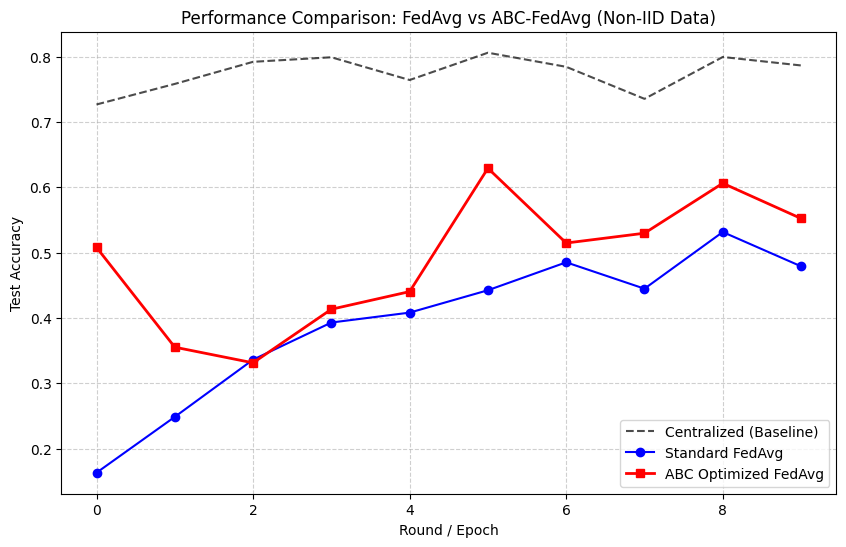

FedAvg Final Accuracy: %47.90
ABC-FedAvg Final Accuracy: %55.22


In [ ]:
plt.figure(figsize=(10, 6))

# Centralized (Referans)
plt.plot(central_acc_history, label='Centralized (Baseline)', linestyle='--', color='black', alpha=0.7)

# FedAvg
plt.plot(fedavg_acc_history, label='Standard FedAvg', marker='o', color='blue')

# ABC Optimized
plt.plot(abc_acc_history, label='ABC Optimized FedAvg', marker='s', color='red', linewidth=2)

plt.xlabel('Round / Epoch')
plt.ylabel('Test Accuracy')
plt.title('Performance Comparison: FedAvg vs ABC-FedAvg (Non-IID Data)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('final_results.png')
plt.show()

# Sonuçları yazdır
print(f"FedAvg Final Accuracy: %{fedavg_acc_history[-1]*100:.2f}")
print(f"ABC-FedAvg Final Accuracy: %{abc_acc_history[-1]*100:.2f}")

In [ ]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.6 MB/s eta 0:00:00


Sistem: cuda üzerinde çalışıyor...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



--- FİNAL DENEY BAŞLIYOR: ResNet-18 & 20 Rounds ---
R 1/20 | FedAvg Acc: %5.9 | ABC Acc: %25.5 (F1: 0.150)
R 2/20 | FedAvg Acc: %17.3 | ABC Acc: %24.2 (F1: 0.226)
R 3/20 | FedAvg Acc: %23.9 | ABC Acc: %31.2 (F1: 0.213)
R 4/20 | FedAvg Acc: %26.3 | ABC Acc: %36.9 (F1: 0.293)
R 5/20 | FedAvg Acc: %25.2 | ABC Acc: %33.4 (F1: 0.220)
R 6/20 | FedAvg Acc: %34.3 | ABC Acc: %40.1 (F1: 0.262)
R 7/20 | FedAvg Acc: %35.3 | ABC Acc: %32.1 (F1: 0.266)
R 8/20 | FedAvg Acc: %44.6 | ABC Acc: %41.8 (F1: 0.300)
R 9/20 | FedAvg Acc: %36.7 | ABC Acc: %41.9 (F1: 0.361)
R 10/20 | FedAvg Acc: %45.1 | ABC Acc: %53.1 (F1: 0.417)
R 11/20 | FedAvg Acc: %37.8 | ABC Acc: %50.4 (F1: 0.451)
R 12/20 | FedAvg Acc: %42.9 | ABC Acc: %51.5 (F1: 0.484)
R 13/20 | FedAvg Acc: %37.4 | ABC Acc: %50.1 (F1: 0.454)
R 14/20 | FedAvg Acc: %46.6 | ABC Acc: %51.5 (F1: 0.457)
R 15/20 | FedAvg Acc: %41.4 | ABC Acc: %49.4 (F1: 0.407)
R 16/20 | FedAvg Acc: %46.9 | ABC Acc: %51.2 (F1: 0.489)
R 17/20 | FedAvg Acc: %40.5 | ABC Acc: %51.0 

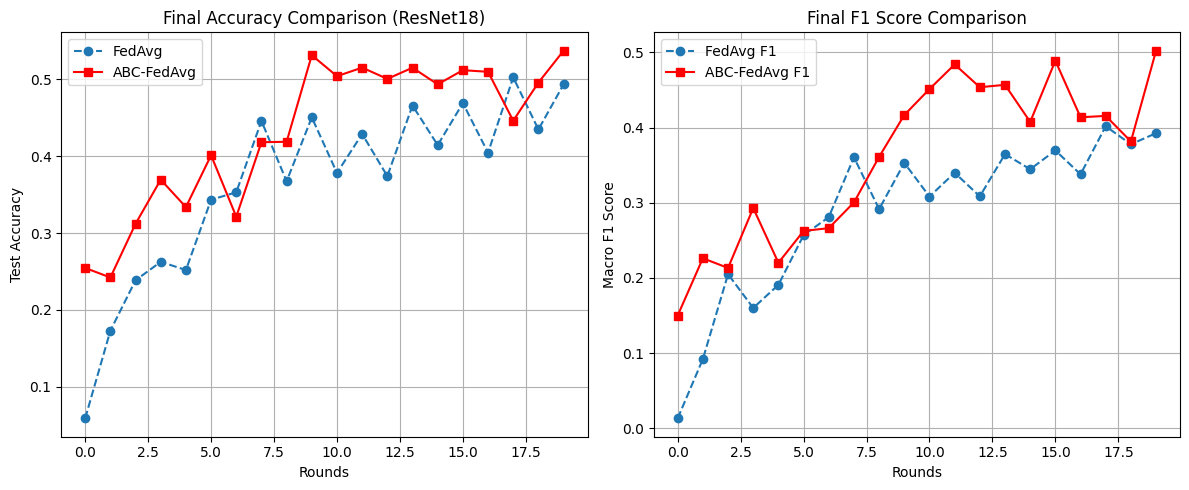

Final ABC Accuracy: %53.73
Final ABC F1 Score: 0.5021


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision.transforms as transforms
from torchvision.models import resnet18
import medmnist
from medmnist import INFO
import numpy as np
import copy
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

# --- 1. AYARLAR (YÜKSEK PERFORMANS) ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Sistem: {device} üzerinde çalışıyor...")

ROUNDS = 20           # Toplam İletişim Turu
LOCAL_EPOCHS = 3      # İstemci başına eğitim tekrarı
NUM_CLIENTS = 5
ABC_LIMIT = 5         # ABC Sabır limiti
ABC_EVALS = 30        # HER TURDA 30 DENEME

# --- 2. VERİ SETİ (ResNet İçin 3 Kanal & Augmentation) ---
def get_data_final():
    data_flag = 'pathmnist'
    info = INFO[data_flag]
    DataClass = getattr(medmnist, info['python_class'])

    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        transforms.Normalize(mean=[.5], std=[.5])
    ])

    test_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[.5], std=[.5])
    ])

    train_dataset = DataClass(split='train', transform=train_transform, download=True)
    test_dataset = DataClass(split='test', transform=test_transform, download=True)

    labels = np.array(train_dataset.labels).flatten()
    sorted_indices = np.argsort(labels)
    shards = np.array_split(sorted_indices, NUM_CLIENTS)
    client_indices = {i: shards[i] for i in range(NUM_CLIENTS)}

    n_classes = len(info['label'])
    return train_dataset, test_dataset, client_indices, n_classes

# --- 3. MODEL: ResNet-18 (MedMNIST Uyarlı) ---
def get_resnet18(n_classes):
    model = resnet18(pretrained=False) # Sıfırdan eğitim
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(512, n_classes)
    return model

# --- 4. DEĞERLENDİRME (Acc + F1 Score) ---
def evaluate(model, loader):
    model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device).long().squeeze()
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    correct = sum([1 for p, t in zip(all_preds, all_targets) if p == t])
    acc = correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    return acc, f1

# --- 5. ABC ALGORİTMASI (DÜZELTİLDİ) ---
class ABC:
    def __init__(self, P, D, lb, ub, limit, evaluationNumber, objective_func):
        self.P, self.D, self.limit = P, D, limit
        self.total_evaluation = evaluationNumber
        self.objective_func = objective_func
        self.lb, self.ub = np.array(lb), np.array(ub)
        self.evaluationNumber = 0
        self.Foods = self.lb + np.random.rand(self.P, self.D) * (self.ub - self.lb)
        self.f = [self.objective_func(food) for food in self.Foods]
        self.trial = np.zeros(P)
        best_idx = np.argmin(self.f)
        self.globalMin = self.f[best_idx]
        self.globalParams = np.copy(self.Foods[best_idx])

    def run(self):
        while self.evaluationNumber < self.total_evaluation:
            for i in range(self.P):
                phi = np.random.uniform(-1, 1, self.D)
                neighbor = np.random.choice([k for k in range(self.P) if k != i])
                new_sol = np.clip(self.Foods[i] + phi * (self.Foods[i] - self.Foods[neighbor]), self.lb, self.ub)
                new_cost = self.objective_func(new_sol)
                self.evaluationNumber += 1
                if new_cost < self.f[i]:
                    self.Foods[i], self.f[i], self.trial[i] = new_sol, new_cost, 0
                else:
                    self.trial[i] += 1
            best_idx = np.argmin(self.f)
            if self.f[best_idx] < self.globalMin:
                self.globalMin = self.f[best_idx]
                self.globalParams = np.copy(self.Foods[best_idx])

        # DÜZELTME BURADA: Artık 2 değer döndürüyor (Parametreler ve Skor)
        return self.globalParams, self.globalMin

# ABC Hedef Fonksiyonu
class FL_ABC_Optimizer_Hybrid:
    def __init__(self, local_weights, base_model, val_loader):
        self.local_weights = local_weights
        self.base_model = base_model
        self.val_loader = val_loader

    def objective_function(self, weights):
        weights = np.maximum(weights, 0)
        norm_w = weights / (np.sum(weights) + 1e-9)

        avg_w = copy.deepcopy(self.local_weights[0])
        for k in avg_w.keys():
            avg_w[k] = avg_w[k] * norm_w[0]
            for i in range(1, len(self.local_weights)):
                avg_w[k] += self.local_weights[i][k] * norm_w[i]

        self.base_model.load_state_dict(avg_w)
        acc, f1 = evaluate(self.base_model, self.val_loader)
        return 1 - (0.5 * acc + 0.5 * f1)

# --- 6. FİNAL SİMÜLASYON ---
train_ds, test_ds, client_idx, n_classes = get_data_final()
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)
val_loader = DataLoader(Subset(test_ds, range(500)), batch_size=128)

fedavg_model = get_resnet18(n_classes).to(device)
abc_model = get_resnet18(n_classes).to(device)

results = {
    'fedavg_acc': [], 'fedavg_f1': [],
    'abc_acc': [], 'abc_f1': []
}

print(f"\n--- FİNAL DENEY BAŞLIYOR: ResNet-18 & 20 Rounds ---")

for r in range(ROUNDS):
    curr_lr = 0.01 * (0.95 ** r)

    # 1. STANDART FEDAVG
    local_w_avg = []
    for i in range(NUM_CLIENTS):
        temp_model = copy.deepcopy(fedavg_model)
        optimizer = optim.SGD(temp_model.parameters(), lr=curr_lr, momentum=0.9, weight_decay=1e-4)
        loader = DataLoader(Subset(train_ds, client_idx[i]), batch_size=32, shuffle=True)
        temp_model.train()
        for _ in range(LOCAL_EPOCHS):
            for img, lbl in loader:
                img, lbl = img.to(device), lbl.to(device).long().squeeze()
                optimizer.zero_grad()
                output = temp_model(img)
                loss = nn.CrossEntropyLoss()(output, lbl)
                loss.backward()
                optimizer.step()
        local_w_avg.append(temp_model.state_dict())

    avg_w = copy.deepcopy(local_w_avg[0])
    for k in avg_w.keys():
        for i in range(1, len(local_w_avg)):
            avg_w[k] += local_w_avg[i][k]
        avg_w[k] = torch.div(avg_w[k], len(local_w_avg))
    fedavg_model.load_state_dict(avg_w)

    acc, f1 = evaluate(fedavg_model, test_loader)
    results['fedavg_acc'].append(acc)
    results['fedavg_f1'].append(f1)

    # 2. ABC OPTIMIZED FEDAVG
    local_w_abc = []
    for i in range(NUM_CLIENTS):
        temp_model = copy.deepcopy(abc_model)
        optimizer = optim.SGD(temp_model.parameters(), lr=curr_lr, momentum=0.9, weight_decay=1e-4)
        loader = DataLoader(Subset(train_ds, client_idx[i]), batch_size=32, shuffle=True)
        temp_model.train()
        for _ in range(LOCAL_EPOCHS):
            for img, lbl in loader:
                img, lbl = img.to(device), lbl.to(device).long().squeeze()
                optimizer.zero_grad()
                output = temp_model(img)
                loss = nn.CrossEntropyLoss()(output, lbl)
                loss.backward()
                optimizer.step()
        local_w_abc.append(temp_model.state_dict())

    # ABC Çalıştır
    optim_wrap = FL_ABC_Optimizer_Hybrid(local_w_abc, abc_model, val_loader)
    solver = ABC(P=5, D=5, lb=[0.1]*5, ub=[1.0]*5, limit=ABC_LIMIT, evaluationNumber=ABC_EVALS, objective_func=optim_wrap.objective_function)

    # HATA BURADA ÇÖZÜLDÜ: best_w, _ = solver.run() artık çalışır.
    best_w, _ = solver.run()

    norm_w = best_w / (np.sum(best_w) + 1e-9)
    final_abc_w = copy.deepcopy(local_w_abc[0])
    for k in final_abc_w.keys():
        final_abc_w[k] = final_abc_w[k] * norm_w[0]
        for i in range(1, len(local_w_abc)):
            final_abc_w[k] += local_w_abc[i][k] * norm_w[i]
    abc_model.load_state_dict(final_abc_w)

    acc_abc, f1_abc = evaluate(abc_model, test_loader)
    results['abc_acc'].append(acc_abc)
    results['abc_f1'].append(f1_abc)

    print(f"R {r+1}/{ROUNDS} | FedAvg Acc: %{acc*100:.1f} | ABC Acc: %{acc_abc*100:.1f} (F1: {f1_abc:.3f})")

# GRAFİK
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(results['fedavg_acc'], label='FedAvg', marker='o', linestyle='--')
plt.plot(results['abc_acc'], label='ABC-FedAvg', marker='s', color='red')
plt.title('Final Accuracy Comparison (ResNet18)')
plt.xlabel('Rounds')
plt.ylabel('Test Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(results['fedavg_f1'], label='FedAvg F1', marker='o', linestyle='--')
plt.plot(results['abc_f1'], label='ABC-FedAvg F1', marker='s', color='red')
plt.title('Final F1 Score Comparison')
plt.xlabel('Rounds')
plt.ylabel('Macro F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('final_thesis_result.png')
plt.show()

print(f"Final ABC Accuracy: %{results['abc_acc'][-1]*100:.2f}")
print(f"Final ABC F1 Score: {results['abc_f1'][-1]:.4f}")